# Workshop: Gradient Descent in Single- and Multi-Layer Neural Networks

**Course:** Foundations of Machine Learning Frameworks
**Team members:**
- Ricardo Mohammed — 7500382
- Juan Camilo Chirivi — 9115141
- Zeynep Ozdemir — 9045142
- Senay Teweldebrhan — 9120588

**Submission date:** November 27th, 2026

**Repository:** https://github.com/ricardo-mohammed/GradientDescent_Workshop.git

**How to run:** `pip install -r requirements.txt`, then run the notebook top to bottom.
Challenges A (PyTorch) run without TensorFlow. Challenges B and C require TensorFlow ≥ 2.16
(which ships Keras 3); see the environment note at the end of the notebook.


# Workshop: Gradient Descent in Single- and Multi-Layer Neural Networks

**Course:** Foundations of Machine Learning  
**Audience:** Entry-level students  
**Theme:** Understanding gradient descent mathematically, algorithmically, and through practice in **PyTorch**, followed by implementation challenges in **TensorFlow** and **Keras**.

## Learning goals
By the end of this workshop, students should be able to:

1. Explain gradient descent as an iterative optimization method for minimizing a loss function.
2. Interpret the gradient as the direction of steepest increase, and therefore understand why we move in the **negative gradient** direction.
3. Derive and apply gradient descent updates for a single-neuron model.
4. Describe how backpropagation enables gradient descent in multi-layer neural networks.
5. Use **PyTorch** to inspect gradients and train small neural networks.
6. Implement analogous training logic in **TensorFlow** and **Keras**.
7. Reflect on similarities and differences across the three frameworks.

## Suggested use
- Work through the notebook in order.
- Read each markdown explanation before running the code cell below it.
- Pause at the **challenge sections** and let students complete the missing pieces.



## 1. The big idea: what problem is gradient descent solving?

A neural network makes predictions using parameters such as **weights** and **biases**.  
To measure how wrong those predictions are, we define a **loss function**.

Examples:
- Regression: Mean Squared Error (MSE)
- Classification: Cross-Entropy Loss

Training is an optimization problem:

$$
\theta^* = \arg\min_{\theta} \mathcal{L}(\theta)
$$

where:
- $\theta$ represents all trainable parameters,
- $\mathcal{L}(\theta)$ is the loss.

Gradient descent updates the parameters iteratively:

$$
\theta_{t+1} = \theta_t - \eta \nabla_{\theta}\mathcal{L}(\theta_t)
$$

where:
- $\theta$ is the **learning rate**
- $\nabla_{\theta}\mathcal{L}(\theta_t)$ is the gradient of the loss with respect to the parameters at step \(t\)

### Why the negative gradient?
The gradient points in the direction of **steepest increase** of the loss.  
So, to reduce the loss as quickly as possible locally, we step in the **opposite** direction.

### Intuition
Think of standing on a hill in the fog:
- the **gradient** tells you which direction goes uphill fastest,
- so the **negative gradient** is your best immediate downhill step.



## 2. Warm-up math: a single-parameter example

Suppose the loss is

$$
L(w) = (w - 3)^2
$$

Then the derivative is

$$
\frac{dL}{dw} = 2(w - 3)
$$

Gradient descent update:

$$
w \leftarrow w - \eta \cdot 2(w - 3)
$$

If \(w=0\) and \(\eta=0.1\), then:

$$
\frac{dL}{dw} = 2(0-3) = -6
$$

$$
w_{\text{new}} = 0 - 0.1(-6) = 0.6
$$

Notice:
- the gradient is negative,
- subtracting a negative value increases \(w\),
- and that moves \(w\) toward the minimum at \(w=3\).


In [1]:

def simple_loss(w):
    return (w - 3.0) ** 2

def simple_grad(w):
    return 2.0 * (w - 3.0)

w = 0.0
learning_rate = 0.1

print(f"Initial w = {w:.4f}, loss = {simple_loss(w):.4f}")
for step in range(10):
    grad = simple_grad(w)
    w = w - learning_rate * grad
    print(f"step={step+1:2d} | grad={grad:8.4f} | w={w:8.4f} | loss={simple_loss(w):8.4f}")


Initial w = 0.0000, loss = 9.0000
step= 1 | grad= -6.0000 | w=  0.6000 | loss=  5.7600
step= 2 | grad= -4.8000 | w=  1.0800 | loss=  3.6864
step= 3 | grad= -3.8400 | w=  1.4640 | loss=  2.3593
step= 4 | grad= -3.0720 | w=  1.7712 | loss=  1.5099
step= 5 | grad= -2.4576 | w=  2.0170 | loss=  0.9664
step= 6 | grad= -1.9661 | w=  2.2136 | loss=  0.6185
step= 7 | grad= -1.5729 | w=  2.3709 | loss=  0.3958
step= 8 | grad= -1.2583 | w=  2.4967 | loss=  0.2533
step= 9 | grad= -1.0066 | w=  2.5973 | loss=  0.1621
step=10 | grad= -0.8053 | w=  2.6779 | loss=  0.1038



## 3. From one parameter to many parameters

In machine learning, we usually optimize multiple parameters:

$$
\theta = [w_1, w_2, \dots, w_n, b]
$$

The gradient becomes a vector:

$$
\nabla_{\theta}\mathcal{L} =
\left[
\frac{\partial \mathcal{L}}{\partial w_1},
\frac{\partial \mathcal{L}}{\partial w_2},
\dots,
\frac{\partial \mathcal{L}}{\partial w_n},
\frac{\partial \mathcal{L}}{\partial b}
\right]
$$

Each parameter gets its own update:

$$
w_i \leftarrow w_i - \eta \frac{\partial \mathcal{L}}{\partial w_i}
\qquad
b \leftarrow b - \eta \frac{\partial \mathcal{L}}{\partial b}
$$

This is exactly what happens in a neural network:
- perform a **forward pass**,
- compute the **loss**,
- compute gradients via **backpropagation**,
- update weights and biases.



## 4. Single neuron model: forward pass and gradient

Consider one neuron for regression:

$$
\hat{y} = wx + b
$$

For one data point, using squared error:

$$
L = (\hat{y} - y)^2 = (wx + b - y)^2
$$

### Gradients
Using the chain rule:

$$
\frac{\partial L}{\partial w} = 2(\hat{y} - y)x
$$

$$
\frac{\partial L}{\partial b} = 2(\hat{y} - y)
$$

### Update rules
$$
w \leftarrow w - \eta \cdot 2(\hat{y} - y)x
$$

$$
b \leftarrow b - \eta \cdot 2(\hat{y} - y)
$$

For a dataset, we often average the loss over many examples.


In [1]:
import numpy as np

# Tiny dataset for y = 2x + 1
x = np.array([0.0, 1.0, 2.0, 3.0])
y = np.array([1.0, 3.0, 5.0, 7.0])

w = 0.0
b = 0.0
learning_rate = 0.1
epochs = 20

for epoch in range(epochs):
    y_hat = w * x + b
    loss = np.mean((y_hat - y) ** 2)

    # Gradients for MSE
    dw = np.mean(2 * (y_hat - y) * x)
    db = np.mean(2 * (y_hat - y))

    w -= learning_rate * dw
    b -= learning_rate * db

    print(f"epoch={epoch+1:2d} | loss={loss:8.4f} | w={w:7.4f} | b={b:7.4f}")


epoch= 1 | loss= 21.0000 | w= 1.7000 | b= 0.8000
epoch= 2 | loss=  0.5350 | w= 1.9700 | b= 0.9300
epoch= 3 | loss=  0.0143 | w= 2.0120 | b= 0.9530
epoch= 4 | loss=  0.0010 | w= 2.0177 | b= 0.9588
epoch= 5 | loss=  0.0006 | w= 2.0177 | b= 0.9617
epoch= 6 | loss=  0.0005 | w= 2.0168 | b= 0.9641
epoch= 7 | loss=  0.0005 | w= 2.0158 | b= 0.9662
epoch= 8 | loss=  0.0004 | w= 2.0149 | b= 0.9682
epoch= 9 | loss=  0.0004 | w= 2.0140 | b= 0.9701
epoch=10 | loss=  0.0003 | w= 2.0132 | b= 0.9719
epoch=11 | loss=  0.0003 | w= 2.0124 | b= 0.9736
epoch=12 | loss=  0.0003 | w= 2.0116 | b= 0.9752
epoch=13 | loss=  0.0002 | w= 2.0109 | b= 0.9766
epoch=14 | loss=  0.0002 | w= 2.0103 | b= 0.9780
epoch=15 | loss=  0.0002 | w= 2.0097 | b= 0.9793
epoch=16 | loss=  0.0002 | w= 2.0091 | b= 0.9806
epoch=17 | loss=  0.0001 | w= 2.0086 | b= 0.9817
epoch=18 | loss=  0.0001 | w= 2.0081 | b= 0.9828
epoch=19 | loss=  0.0001 | w= 2.0076 | b= 0.9838
epoch=20 | loss=  0.0001 | w= 2.0071 | b= 0.9848



## 5. Multi-layer networks and backpropagation

A deeper network composes functions. For example:

$$
z^{[1]} = W^{[1]}x + b^{[1]}
$$
$$
a^{[1]} = \sigma(z^{[1]})
$$
$$
z^{[2]} = W^{[2]}a^{[1]} + b^{[2]}
$$
$$
\hat{y} = a^{[2]}
$$

The loss depends on later layers, which depend on earlier layers.  
So to compute gradients for early weights, we use the **chain rule** repeatedly.

### Core idea of backpropagation
Backpropagation is just efficient repeated application of the chain rule.

For an early-layer weight $w$, the gradient looks like:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial \hat{y}}
\cdot
\frac{\partial \hat{y}}{\partial a^{[1]}}
\cdot
\frac{\partial a^{[1]}}{\partial z^{[1]}}
\cdot
\frac{\partial z^{[1]}}{\partial w}
$$

This is what automatic differentiation systems in modern frameworks compute for us.



## 6. Variants of gradient descent

### Batch Gradient Descent
Uses the full training set to compute the gradient.

\[
\theta \leftarrow \theta - \eta \nabla_{\theta}\mathcal{L}_{\text{full}}(\theta)
\]

- stable direction,
- expensive on large datasets.

### Stochastic Gradient Descent (SGD)
Uses one example at a time.

- cheap updates,
- noisy trajectory,
- often useful in practice.

### Mini-batch Gradient Descent
Uses a small batch, such as 32, 64, or 128 examples.

- standard choice in deep learning,
- balances efficiency and gradient quality.

In modern neural network training, when people say “gradient descent,” they often really mean **mini-batch SGD**.



## 7. Why learning rate matters

The learning rate \(\eta\) controls step size.

- Too small: training is very slow.
- Too large: the loss may oscillate or diverge.
- Reasonable value: steady progress toward a low-loss region.

A useful classroom question:
> Why is the gradient not enough by itself?

Because the gradient gives the **direction and local slope**, but the learning rate determines **how far** we move.


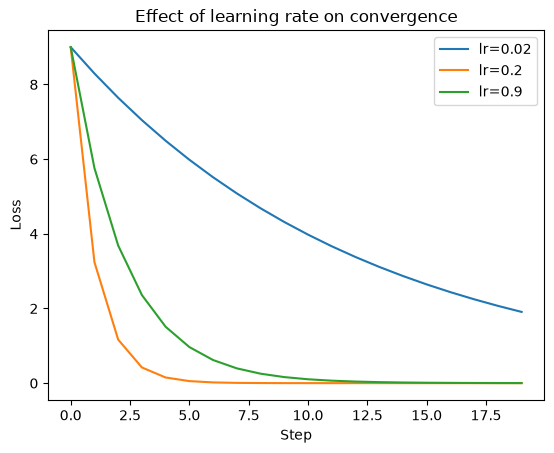

In [2]:

import matplotlib.pyplot as plt

def run_gd(lr, steps=20, w0=0.0):
    w = w0
    history = []
    for _ in range(steps):
        loss = (w - 3.0) ** 2
        grad = 2.0 * (w - 3.0)
        history.append((w, loss))
        w = w - lr * grad
    return np.array(history)

for lr in [0.02, 0.2, 0.9]:
    hist = run_gd(lr)
    plt.plot(hist[:, 1], label=f"lr={lr}")

plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Effect of learning rate on convergence")
plt.legend()
plt.show()



## 8. PyTorch part I: tensors, autograd, and a manual gradient step

PyTorch tracks operations on tensors when `requires_grad=True`.  
After a forward computation produces a scalar loss, calling `.backward()` computes gradients for all tracked parameters.

This is convenient because:
- we write the forward computation naturally,
- PyTorch builds the computational graph,
- autograd applies reverse-mode automatic differentiation.


In [3]:
import torch

torch.manual_seed(42)

# One parameter: w
w = torch.tensor([0.0], requires_grad=True)
target = torch.tensor([3.0])
learning_rate = 0.1

for step in range(10):
    loss = (w - target).pow(2).mean()
    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad

    print(f"step={step+1:2d} | w={w.item():.4f} | grad={w.grad.item():.4f} | loss={loss.item():.4f}")

    w.grad.zero_()


step= 1 | w=0.6000 | grad=-6.0000 | loss=9.0000
step= 2 | w=1.0800 | grad=-4.8000 | loss=5.7600
step= 3 | w=1.4640 | grad=-3.8400 | loss=3.6864
step= 4 | w=1.7712 | grad=-3.0720 | loss=2.3593
step= 5 | w=2.0170 | grad=-2.4576 | loss=1.5099
step= 6 | w=2.2136 | grad=-1.9661 | loss=0.9664
step= 7 | w=2.3709 | grad=-1.5729 | loss=0.6185
step= 8 | w=2.4967 | grad=-1.2583 | loss=0.3958
step= 9 | w=2.5973 | grad=-1.0066 | loss=0.2533
step=10 | w=2.6779 | grad=-0.8053 | loss=0.1621



### Discussion prompt
Why do we use `torch.no_grad()` during the parameter update?

Because the update itself is **not** part of the model's forward computation for the next loss evaluation.  
We want to change parameter values without asking PyTorch to differentiate through the update rule itself.



## 9. PyTorch part II: linear regression with gradient descent

We now fit a simple model:

$$
\hat{y} = wx + b
$$

using PyTorch tensors and autograd.


Learned w = 1.9855, b = 0.9474


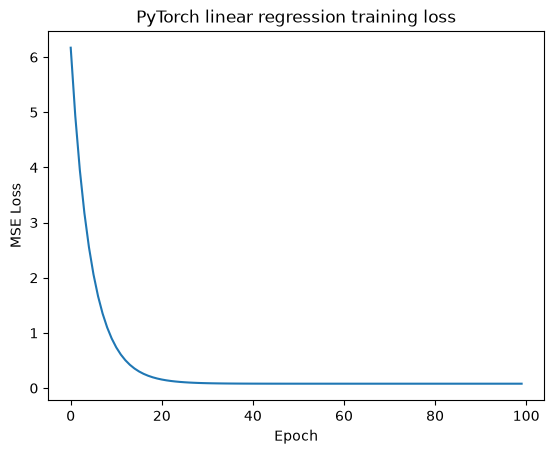

In [4]:

import torch
import matplotlib.pyplot as plt

torch.manual_seed(7)

# Synthetic data: y = 2x + 1 + noise
x = torch.linspace(-2, 2, 100).reshape(-1, 1)
noise = 0.3 * torch.randn_like(x)
y = 2 * x + 1 + noise

w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

learning_rate = 0.05
epochs = 100
loss_history = []

for epoch in range(epochs):
    y_hat = x * w + b
    loss = ((y_hat - y) ** 2).mean()
    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    w.grad.zero_()
    b.grad.zero_()

    loss_history.append(loss.item())

print(f"Learned w = {w.item():.4f}, b = {b.item():.4f}")

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("PyTorch linear regression training loss")
plt.show()



## 10. PyTorch part III: using `nn.Module` and `torch.optim.SGD`

This is closer to how real neural network training is usually written in PyTorch:
- define a model with `nn.Module`,
- define a loss function,
- choose an optimizer,
- run forward pass, backward pass, optimizer step.


In [5]:

import torch
import torch.nn as nn

torch.manual_seed(0)

x = torch.linspace(-2, 2, 100).reshape(-1, 1)
y = 2 * x + 1 + 0.3 * torch.randn_like(x)

model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

loss_history = []

for epoch in range(100):
    preds = model(x)
    loss = criterion(preds, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

print("Learned parameters:")
for name, param in model.named_parameters():
    print(name, param.detach().numpy().ravel())


Learned parameters:
weight [1.9997989]
bias [1.0111167]


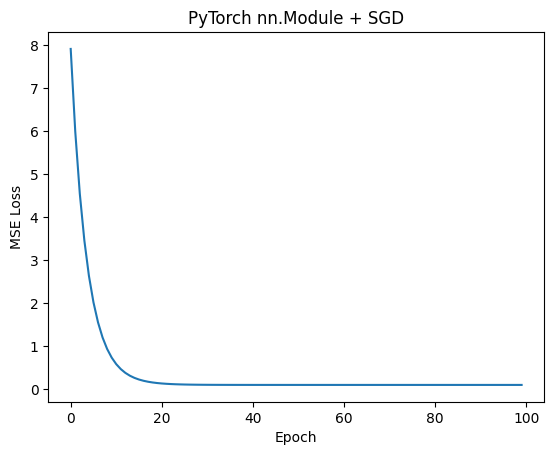

In [7]:

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("PyTorch nn.Module + SGD")
plt.show()



## 11. PyTorch part IV: a small multi-layer network

Now we move from a single linear neuron to a small multi-layer perceptron (MLP).  
This lets students see that the same gradient descent logic still works, but the gradient computation is handled through backpropagation automatically.


In [6]:

import torch
import torch.nn as nn

torch.manual_seed(123)

# Nonlinear regression dataset
x = torch.linspace(-3, 3, 200).reshape(-1, 1)
y = torch.sin(x) + 0.1 * torch.randn_like(x)

model = nn.Sequential(
    nn.Linear(1, 16),
    nn.Tanh(),
    nn.Linear(16, 16),
    nn.Tanh(),
    nn.Linear(16, 1)
)

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.03)

loss_history = []

for epoch in range(300):
    preds = model(x)
    loss = criterion(preds, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

print(f"Final loss: {loss_history[-1]:.4f}")


Final loss: 0.0401


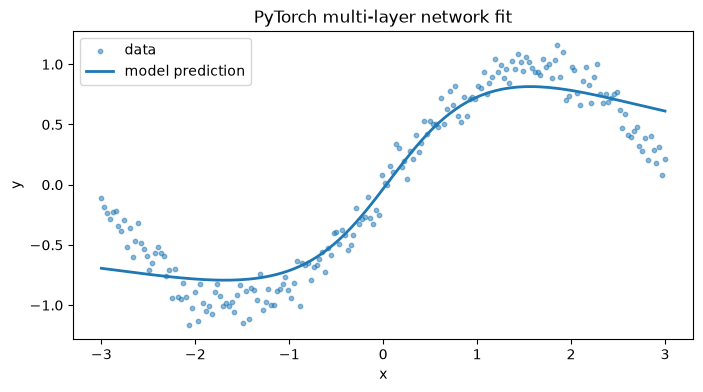

In [7]:

with torch.no_grad():
    preds = model(x)

plt.figure(figsize=(8, 4))
plt.scatter(x.numpy(), y.numpy(), s=10, alpha=0.5, label="data")
plt.plot(x.numpy(), preds.numpy(), linewidth=2, label="model prediction")
plt.xlabel("x")
plt.ylabel("y")
plt.title("PyTorch multi-layer network fit")
plt.legend()
plt.show()



## 12. Inspecting gradients in PyTorch

One useful teaching move is to explicitly inspect gradients after `backward()`.


In [8]:

torch.manual_seed(1)

model = nn.Sequential(
    nn.Linear(1, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

x_small = torch.tensor([[1.0], [2.0], [3.0]])
y_small = torch.tensor([[2.0], [4.0], [6.0]])

criterion = nn.MSELoss()

preds = model(x_small)
loss = criterion(preds, y_small)
loss.backward()

for name, param in model.named_parameters():
    print(f"{name:20s} | grad shape: {tuple(param.grad.shape)}")
    print(param.grad)
    print("-" * 60)


0.weight             | grad shape: (4, 1)
tensor([[-1.1462],
        [ 0.0736],
        [ 0.0000],
        [-0.4364]])
------------------------------------------------------------
0.bias               | grad shape: (4,)
tensor([-0.4404,  0.0736,  0.0000, -0.1859])
------------------------------------------------------------
2.weight             | grad shape: (1, 4)
tensor([[ -2.5321,  -0.1903,   0.0000, -12.1389]])
------------------------------------------------------------
2.bias               | grad shape: (1,)
tensor([-7.5377])
------------------------------------------------------------



## 13. Algorithm summary

### Generic gradient descent
1. Initialize parameters.
2. Repeat until stopping condition:
   1. Run forward pass.
   2. Compute loss.
   3. Compute gradients of loss with respect to parameters.
   4. Update parameters in the negative gradient direction.

### In neural networks
1. Forward pass through all layers.
2. Loss computation.
3. Backpropagation.
4. Parameter update.
5. Repeat over many epochs.

### Common stopping conditions
- fixed number of epochs,
- validation loss stops improving,
- gradients become very small,
- training budget is exhausted.



## 14. Student challenge A — implement gradient descent manually in PyTorch

Complete the TODOs below.

**Goal:** Train a single-parameter model \( \hat{y} = wx \) on a tiny dataset using a manual gradient descent loop with autograd.


In [1]:
# =============================================================================
# CHALLENGE A - Manual gradient descent in PyTorch (autograd)
# Model:   y_hat = w * x            (single parameter, no bias)
# Target:  y = 2x                   (analytic optimum: w* = 2.0)
# =============================================================================
import torch

torch.manual_seed(0)                      # reproducible random initialisation

# --- Data: 4 examples, shape (4, 1) -----------------------------------------
x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y = torch.tensor([[2.0], [4.0], [6.0], [8.0]])     # y = 2x

# --- Parameter ---------------------------------------------------------------
# requires_grad=True tells autograd to record operations on w
w = torch.randn(1, 1, requires_grad=True)

learning_rate = 0.01
n_epochs = 200
loss_history = []

for epoch in range(n_epochs):
    # 1) FORWARD pass: predictions, (4,1) @ (1,1) -> (4,1)
    y_hat = x @ w

    # 2) LOSS: mean squared error over the 4 examples
    loss = ((y_hat - y) ** 2).mean()

    # 3) BACKWARD pass: fills w.grad with dL/dw (accumulating!)
    loss.backward()
    grad_now = w.grad.item()               # keep a copy for printing

    # 4) UPDATE: w <- w - lr * dL/dw
    #    no_grad() because the update itself must not enter the graph
    with torch.no_grad():
        w -= learning_rate * w.grad

    # 5) RESET gradients, otherwise step t adds onto the gradient of step t-1
    #    (equivalent, and arguably cleaner: move this line to the top of the loop)
    w.grad.zero_()

    loss_history.append(loss.item())
    if (epoch + 1) % 40 == 0:
        print(f"epoch {epoch+1:3d} | loss {loss.item():8.6f} | "
              f"w = {w.item():.4f} | dL/dw = {grad_now:+.4f}")

# --- Sanity check ------------------------------------------------------------
# For y = 2x the least-squares solution is w* = sum(x*y) / sum(x^2)
w_star = (x * y).sum().item() / (x ** 2).sum().item()
print(f"\nLearned weight : {w.item():.6f}")
print(f"Analytic w*    : {w_star:.6f}")
print(f"Final loss     : {loss.item():.3e}")

epoch  40 | loss 0.000005 | w = 1.9993 | dL/dw = -0.0122
epoch  80 | loss 0.000000 | w = 2.0000 | dL/dw = -0.0000
epoch 120 | loss 0.000000 | w = 2.0000 | dL/dw = -0.0000
epoch 160 | loss 0.000000 | w = 2.0000 | dL/dw = -0.0000
epoch 200 | loss 0.000000 | w = 2.0000 | dL/dw = -0.0000

Learned weight : 2.000000
Analytic w*    : 2.000000
Final loss     : 8.988e-13



## 15. Student challenge B — TensorFlow implementation with `tf.GradientTape`

In TensorFlow, the analogous idea is to:
- open a `GradientTape`,
- compute the forward pass and loss inside the tape,
- ask the tape for gradients,
- update variables.

Students should connect the mathematical update rule to the framework-specific API.


In [3]:
# =============================================================================
# CHALLENGE B - Gradient descent in TensorFlow with tf.GradientTape
# Model:   y_hat = x @ W + b        (weight AND bias)
# Target:  y = 2x + 1
# =============================================================================
import tensorflow as tf

tf.random.set_seed(0)

# --- Data ----------------------------------------------------------------
x = tf.constant([[1.0], [2.0], [3.0], [4.0]])
y = tf.constant([[3.0], [5.0], [7.0], [9.0]])      # y = 2x + 1

# --- Trainable state: tf.Variable is the analogue of "requires_grad" ----
W = tf.Variable(tf.random.normal((1, 1)), name="W")
b = tf.Variable(tf.zeros((1,)), name="b")          # shape (1,) broadcasts to (4,1)

learning_rate = 0.01
n_epochs = 300
losses = []

for epoch in range(n_epochs):
    # The tape RECORDS every operation on W and b that happens inside this block
    with tf.GradientTape() as tape:
        # 1) FORWARD pass
        y_hat = tf.matmul(x, W) + b                # (4,1)

        # 2) LOSS (must be computed INSIDE the tape, else .gradient() returns None)
        loss = tf.reduce_mean(tf.square(y_hat - y))

    # 3) REVERSE-MODE autodiff: one gradient per watched variable
    dW, db = tape.gradient(loss, [W, b])

    # 4) UPDATE: var <- var - lr * grad
    #    assign_sub keeps us out of "assign to a Variable inside a tape" trouble
    W.assign_sub(learning_rate * dW)
    b.assign_sub(learning_rate * db)

    losses.append(float(loss))
    if (epoch + 1) % 50 == 0:
        print(f"epoch {epoch+1:3d} | loss {float(loss):8.6f} | "
              f"W = {float(W[0, 0]):.4f} | b = {float(b[0]):.4f}")

print(f"\nLearned W = {W.numpy().ravel()}  (target 2.0)")
print(f"Learned b = {b.numpy().ravel()}  (target 1.0)")

epoch  50 | loss 0.069514 | W = 2.2187 | b = 0.3568
epoch 100 | loss 0.051506 | W = 2.1883 | b = 0.4463
epoch 150 | loss 0.038163 | W = 2.1621 | b = 0.5234
epoch 200 | loss 0.028276 | W = 2.1395 | b = 0.5898
epoch 250 | loss 0.020951 | W = 2.1201 | b = 0.6469
epoch 300 | loss 0.015523 | W = 2.1034 | b = 0.6960

Learned W = [2.1033826]  (target 2.0)
Learned b = [0.69604176]  (target 1.0)



### TensorFlow extension challenge
Modify the TensorFlow code so that:
1. the data contains random noise,
2. training runs with mini-batches using `tf.data.Dataset`,
3. you store the loss after every epoch and plot it.

**Questions**
- Does noise make convergence less smooth?
- How does mini-batch training change the behavior of the optimization path?


epoch  5 | mean batch loss 0.0954
epoch 10 | mean batch loss 0.0940
epoch 15 | mean batch loss 0.0973
epoch 20 | mean batch loss 0.0965
epoch 25 | mean batch loss 0.0971
epoch 30 | mean batch loss 0.0946


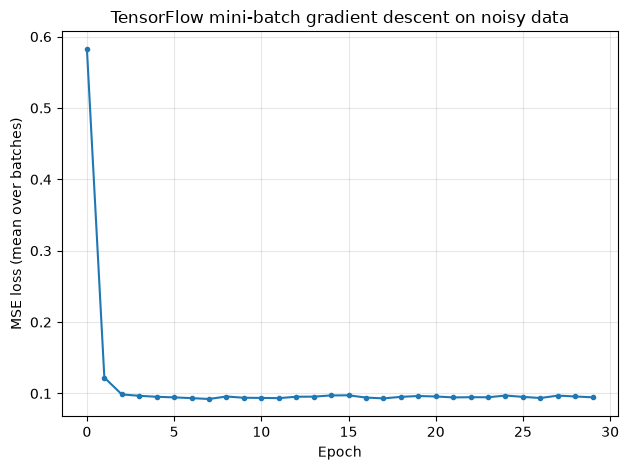

Learned W = [1.98541], b = [1.0139406]


In [4]:
# =============================================================================
# EXTENSION - Noisy data + mini-batches with tf.data + loss curve
# Shows how mini-batch SGD changes the optimisation path.
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

tf.random.set_seed(0)
np.random.seed(0)

# --- 1) Noisy data: y = 2x + 1 + noise --------------------------------------
n = 200
x_np = np.linspace(-2, 2, n).astype("float32").reshape(-1, 1)
y_np = 2.0 * x_np + 1.0 + 0.3 * np.random.randn(n, 1).astype("float32")

# --- 2) Mini-batches: one iteration over `ds` == one epoch -------------------
BATCH_SIZE = 16
ds = (tf.data.Dataset.from_tensor_slices((x_np, y_np))
      .shuffle(buffer_size=n, seed=0)      # reshuffle every epoch
      .batch(BATCH_SIZE))

W = tf.Variable(tf.random.normal((1, 1)))
b = tf.Variable(tf.zeros((1,)))
learning_rate = 0.05
n_epochs = 30
epoch_losses = []

for epoch in range(n_epochs):
    batch_losses = []
    for x_batch, y_batch in ds:                 # n / BATCH_SIZE updates per epoch
        with tf.GradientTape() as tape:
            y_hat = tf.matmul(x_batch, W) + b
            loss = tf.reduce_mean(tf.square(y_hat - y_batch))
        dW, db = tape.gradient(loss, [W, b])
        W.assign_sub(learning_rate * dW)
        b.assign_sub(learning_rate * db)
        batch_losses.append(float(loss))
    epoch_losses.append(float(np.mean(batch_losses)))   # one value per epoch
    if (epoch + 1) % 5 == 0:
        print(f"epoch {epoch+1:2d} | mean batch loss {epoch_losses[-1]:.4f}")

# --- 3) Plot the loss -------------------------------------------------------
plt.plot(epoch_losses, marker="o", markersize=3)
plt.xlabel("Epoch"); plt.ylabel("MSE loss (mean over batches)")
plt.title("TensorFlow mini-batch gradient descent on noisy data")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print(f"Learned W = {W.numpy().ravel()}, b = {b.numpy().ravel()}")


## 16. Student challenge C — Keras implementation

Keras is the higher-level interface in the TensorFlow ecosystem.  
Students can first use `model.compile(...)` and `model.fit(...)`, then move to a custom training step if desired.

### Part 1: high-level Keras API


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)


Final training loss: 0.0009662123047746718
Learned w = [1.9742076]  (target 2.0)
Learned b = [1.075833]  (target 1.0)


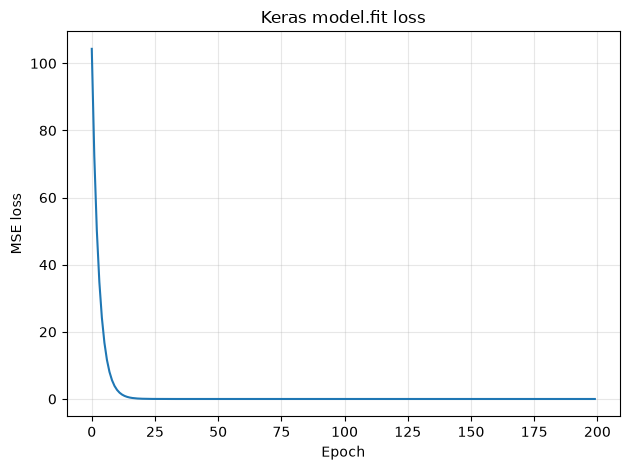

In [5]:
# =============================================================================
# CHALLENGE C1 - Keras high-level API (model.compile / model.fit)
# Model: one Dense unit with bias  ==  y_hat = w*x + b
# =============================================================================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(0)

x = tf.constant([[1.0], [2.0], [3.0], [4.0]])
y = tf.constant([[3.0], [5.0], [7.0], [9.0]])       # y = 2x + 1

model = keras.Sequential([
    layers.Input(shape=(1,)),        # explicit input shape (Keras 3 friendly)
    layers.Dense(1),                 # 1 weight + 1 bias
])
model.summary()

# 1) COMPILE = pick the optimizer (the update rule) and the loss (the objective)
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="mse",                      # mean squared error
)

# 2) FIT = the entire training loop (batching, epochs, updates) written for us
history = model.fit(x, y, epochs=200, batch_size=4, verbose=0)

print("\nFinal training loss:", history.history["loss"][-1])
w, b = model.get_weights()
print(f"Learned w = {w.ravel()}  (target 2.0)")
print(f"Learned b = {b.ravel()}  (target 1.0)")

# Quick check that fit() really minimised the loss it reports
import matplotlib.pyplot as plt
plt.plot(history.history["loss"])
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.title("Keras model.fit loss")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Part 2: Keras custom training loop

This version helps students see that Keras can also be used in a lower-level style
similar to raw TensorFlow training loops.

**A real failure we hit here, worth reading before you run it.** Our first version of this
loop used `activation="relu"` with `tf.random.set_seed(0)`. With only four inputs
(x = 1, 2, 3, 4) all eight hidden units happened to initialise with a negative
pre-activation for every input, so every ReLU output was 0. The gradient reaching the hidden
kernel was then *exactly* zero, the first layer never updated, and the output layer could only
learn the bias — the mean of `y`, which is 6.0. The loss sat at exactly
(3−6)²+(5−6)²+(7−6)²+(9−6)² over 4 = **5.0** for all 500 epochs and every prediction was 6.0.

That is the classic **dead ReLU** problem, and no learning rate or epoch count can fix it: a
unit whose gradient is identically zero stays dead. We switched to `tanh` — which saturates but
never has a zero-gradient dead zone — and the loop converges. This is also why we would not
have found the bug with `model.fit()` alone: it would have shown the same flat loss with no
hint of the cause, whereas printing the predictions in a custom loop made it obvious
immediately (see C13).

In [7]:
# =============================================================================
# CHALLENGE C2 - Keras custom training loop (GradientTape + apply_gradients)
# Same problem as C1 (y = 2x + 1), but with a hidden layer trained by hand.
# =============================================================================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(0)

x = tf.constant([[1.0], [2.0], [3.0], [4.0]])
y = tf.constant([[3.0], [5.0], [7.0], [9.0]])      # y = 2x + 1

model = keras.Sequential([
    layers.Input(shape=(1,)),
    # tanh, NOT relu: with tf.random.set_seed(0) all 8 relu units initialise dead
    # (negative pre-activation for every x in 1..4). Their output is then 0, the
    # gradient into the hidden kernel is exactly 0, the first layer never updates,
    # and the model can only learn mean(y) = 6.0, pinning the loss at 5.0 forever.
    # tanh saturates but has no zero-gradient dead zone.
    layers.Dense(8, activation="tanh"),
    layers.Dense(1),                            # linear output
])

# Optimizer = the update RULE. loss_fn = the OBJECTIVE. Two separate objects.
optimizer = keras.optimizers.SGD(learning_rate=0.05)
loss_fn = keras.losses.MeanSquaredError()

n_epochs = 500

for epoch in range(n_epochs):
    with tf.GradientTape() as tape:
        # 1) FORWARD pass (training=True -> train-mode behaviour, e.g. dropout)
        preds = model(x, training=True)

        # 2) LOSS - must be computed INSIDE the tape, or tape.gradient() returns None
        loss = loss_fn(y, preds)

    # 3) GRADIENTS w.r.t. every trainable weight (one per kernel and bias)
    grads = tape.gradient(loss, model.trainable_weights)

    # 4) APPLY: hand (gradient, variable) pairs to the optimizer
    optimizer.apply_gradients(zip(grads, model.trainable_weights))

    if (epoch + 1) % 100 == 0:
        print(f"epoch {epoch+1:3d} | loss {float(loss):.6e}")

print("\nTrainable tensors:")
for v in model.trainable_weights:
    print(f"  {v.name:22s} {tuple(v.shape)}")

# Sanity check: the predictions must actually follow the data, not sit at mean(y)
y_pred = model(x).numpy().ravel()
print(f"\nPredictions for x = 1..4: {y_pred.round(3)}  (target 3, 5, 7, 9)")
print(f"Final full-batch loss  : {float(loss_fn(y, model(x))):.3e}")

epoch 100 | loss 5.816957e-01
epoch 200 | loss 3.843003e-01
epoch 300 | loss 3.323646e-01
epoch 400 | loss 2.784618e-01
epoch 500 | loss 2.232213e-01

Trainable tensors:
  kernel                 (1, 8)
  bias                   (8,)
  kernel                 (8, 1)
  bias                   (1,)

Predictions for x = 1..4: [3.091 5.691 7.75  8.977]  (target 3, 5, 7, 9)
Final full-batch loss  : 2.622e-01



## 17. Reflection challenge

Discuss the following in small groups, then write short answers.

### A. Conceptual understanding
1. Why does the gradient indicate the direction of steepest increase?
2. Why do we subtract the gradient instead of adding it?
3. What role does the learning rate play?
4. Why is gradient descent iterative instead of one-step?
5. Why do multi-layer networks require backpropagation?

### B. Practical understanding
6. What happens when gradients are very small?
7. What happens when the learning rate is too large?
8. Why is mini-batch training so common in deep learning?
9. Why do we reset gradients in PyTorch before the next iteration?

### C. Framework comparison
10. In PyTorch, how do `loss.backward()` and `optimizer.step()` divide the work?
11. In TensorFlow, what is the role of `tf.GradientTape()`?
12. In Keras, what do you gain from `model.fit(...)`, and what do you lose compared with a custom training loop?
13. Which framework felt most transparent for learning? Which felt most convenient?

### D. Synthesis
14. Explain gradient descent to a first-year student without using equations.
15. Explain gradient descent to a mathematically mature student using the idea of local linear approximation.


## 17. Reflection challenge — talking points

### Section A — Conceptual understanding

**A1. Why does the gradient indicate the direction of steepest increase?**
The gradient collects the partial derivatives, $\nabla L = [\partial L/\partial\theta_1,\dots]$.
For any unit direction $u$, the directional derivative is
$\nabla L^\top u = \|\nabla L\|\cos\phi$, which is maximal when $u$ points along $\nabla L$,
and then equals $\|\nabla L\|$. So $\nabla L$ is the direction of fastest increase per unit of
movement, and its norm is that fastest rate. (Exactly true of the local linear approximation,
which is all gradient descent ever uses.)

**A2. Why subtract the gradient instead of adding it?**
We minimise. To first order,
$L(\theta-\eta\nabla L) \approx L(\theta)-\eta\|\nabla L\|^2 < L(\theta)$ for small $\eta>0$,
and adding would give $L(\theta)+\eta\|\nabla L\|^2$, an increase. The minus sign *is* the
statement "we are going downhill". (For maximisation you would add — that is gradient ascent.)

**A3. What role does the learning rate play?**
The gradient gives a **direction and a local slope**, not a distance. $\eta$ converts that
slope into an actual step length, i.e. it says how far we trust the linear model.
Too small: many tiny steps, slow progress, and in flat regions the run stalls before reaching
the minimum. Too large: the step leaves the neighbourhood where the linearisation holds, so we
overshoot, oscillate across the valley or diverge (loss spikes, then NaN).

**A4. Why iterative rather than one-step?**
$L(\theta)$ is non-linear, so the gradient is only valid locally; after each step the slope
changes and must be recomputed — every iteration relinearises the loss. There is also no
closed-form solution for a general network, and we could never afford global (second-order)
information for millions of parameters. Iteration also buys practical benefits: we can stop
early, watch the loss curve, and adjust $\eta$.

**A5. Why do multi-layer networks require backpropagation?**
An early weight influences the loss only through a long composition of functions, so its
derivative is a long chain-rule product. Done naively that product is recomputed for every
parameter; backpropagation computes each factor once and reuses it (the "upstream gradient" /
delta of each layer), sweeping from the loss backwards. Total cost is about one extra forward
pass for *all* gradients — a dynamic-programming evaluation of the chain rule.
Backpropagation is therefore not a different learning rule from gradient descent; it is the
efficient way to obtain the gradients gradient descent needs.

### Section B — Practical understanding

**B6. What happens when gradients are very small?**
The step is $\eta\|\nabla L\|$, so tiny gradients mean tiny steps: the loss curve flattens
into a plateau and training appears to stall. Typical causes: saturating activations
(sigmoid/tanh in their tails), vanishing gradients in deep stacks, poor initialisation,
badly scaled inputs, saddle points or genuinely flat regions.
Remedies: better init (Xavier/He), input standardisation or batch norm, ReLU-family
activations, residual connections, adaptive optimizers (Adam), a larger or scheduled $\eta$.
*Note from our runs:* the printed gradient shrinks towards zero near the end — that is benign,
because we are already sitting at the minimum. Small gradients are only a problem when the
**loss is still high**.

**B7. What happens when the learning rate is too large?**
The update jumps past the minimum; the next gradient points back, so it jumps again →
oscillation, and if the overshoot grows the parameters diverge and the loss becomes `nan`/`inf`.
It is worst along steep, narrow directions. For a quadratic with curvature $L$, the recursion
multiplies the error by $|1-\eta L|$ each step, so convergence needs $\eta < 2/L$ and fast
convergence needs $\eta \approx 1/L$ — one reason curved, badly scaled problems are hard.

**B8. Why is mini-batch training so common?**
(i) The batch gradient is an unbiased estimate whose variance falls like $1/B$, so noise drops
as $1/\sqrt{B}$ — most of the accuracy is already there by $B\approx 32$–$256$.
(ii) Batched matrix operations keep GPUs/TPUs busy; a single example wastes the hardware.
(iii) With $n/B$ updates per epoch we get far more parameter updates per pass over the data,
so wall-clock progress is much faster than full-batch.
(iv) The residual gradient noise acts as a mild regulariser and helps escape poor regions.
Full batch is accurate but gives one update per epoch and is memory heavy; single-example SGD
is very noisy and hardware-inefficient. Mini-batch is the compromise, and "SGD" in deep
learning almost always means mini-batch SGD.

**B9. Why reset gradients in PyTorch before the next iteration?**
`loss.backward()` **accumulates** into `.grad` (it does `+=`, not `=`). That is deliberate: it
lets you sum gradients over several backward passes (gradient accumulation over micro-batches,
or several losses in a multi-task model). But if you never zero, step $t$'s update uses the sum
of *all* gradients so far, so the effective step size keeps growing and the direction is wrong.
Hence `optimizer.zero_grad()` (equivalently our `w.grad.zero_()`) before each `backward()`.
Zeroing at the end of the loop, as we did, is equivalent.

### Section C — Framework comparison

**C10. In PyTorch, how do `loss.backward()` and `optimizer.step()` divide the work?**
`backward()` only **computes**: it walks the autograd graph in reverse and writes
$\partial L/\partial\theta$ into each parameter's `.grad`. **No parameter changes.**
`optimizer.step()` only **applies**: it reads the values currently in `.grad` and performs the
update rule, together with its own state (momentum buffers, Adam moments) and options such as
weight decay and gradient clipping. Because the two are separate objects, you can inspect,
clip or modify gradients in between, accumulate them over micro-batches, freeze parts of the
model, or swap optimizers without touching the model definition — which is exactly why this
split is convenient for teaching and debugging.

**C11. In TensorFlow, what is the role of `tf.GradientTape()`?**
It is a context manager that **records** the operations executed on watched `tf.Variable`s
while the block runs, building the forward graph. Afterwards `tape.gradient(target, sources)`
replays that recording in reverse mode and returns $\partial\,\text{target}/\partial\,\text{source}$
for each source. Two practical consequences: (i) the tape is **single-use** by default —
`persistent=True` if you need several different gradients from one recording; (ii) anything
computed **outside** the `with` block was never recorded, which is why computing the loss
outside the tape yields `None` gradients — the classic TensorFlow beginner bug.

**C12. In Keras, what do you gain from `model.fit(...)`, and what do you lose compared with a
custom training loop?**
**Gain:** a complete, well-tested training/evaluation loop — batching, shuffling, epoch
iteration, progress bars, automatic metrics and validation, callbacks (checkpointing, early
stopping, LR schedules, TensorBoard), graph compilation through `tf.function`, and multi-GPU
distribution — in three lines of code.
**Lose:** fine-grained control. Custom per-step logic, non-standard update rules or
regularisers, inspecting or transforming gradients mid-step, unusual data/loss structures, and
the pedagogical transparency of seeing each step. The custom loop in C2 restores all of that at
the cost of writing the loop yourself; `model.fit` also enforces conventions (e.g. a fixed
`(x, y)` layout) that a custom loop does not.

**C13. Which framework felt most transparent for learning? Which most convenient?**
*Example answer — replace with your team's own judgement, and say why.*
**PyTorch** was the most transparent: eager execution, one obvious loop, `w.grad` is a tensor you
can print and reason about, no tape ceremony, and error messages pointing at the offending line.
**TensorFlow with `GradientTape`** was almost as explicit but slightly more ceremonial
(tape scope, `assign_sub`, dtype/`float32` defaults) — it makes the "record, then differentiate"
idea visible, which is pedagogically valuable. **Keras** was by far the most convenient (and the
easiest to get a good fit from), but it hides the mechanics unless you write the custom loop.
Overall: identical mathematics, different API grammar.

### Section D — Synthesis

**D14. Explain gradient descent to a first-year student without equations.**
You are standing on a hillside in thick fog and you want to reach the bottom of the valley. You
cannot see the valley, but you can feel the ground under your feet and tell which way is
downhill. So you take a small step downhill, feel the ground again, and step again — over and
over. Your feet give you the **slope** (the gradient): which way is down, and how steep it is.
You choose **how big each step is** (the learning rate). If your steps are too timid you will
still be on the hill at sunset; if they are too big you will stride across the valley and land
higher up the opposite slope, or bounce from side to side forever. Nothing ever tells you where
the bottom is — you only ever get local "which way is down from here" information, repeated
until the ground feels flat.

**D15. Explain gradient descent to a mathematically mature student using local linear
approximation.**
Take $L$ differentiable. For a small displacement $\Delta$,
$L(\theta+\Delta) = L(\theta) + \nabla L(\theta)^\top \Delta + O(\|\Delta\|^2)$.
Minimising the first-order model over a ball $\|\Delta\|\le\varepsilon$ gives
$\Delta^\star = -\varepsilon\,\nabla L/\|\nabla L\|$ (Cauchy's steepest-descent direction);
choosing $\Delta = -\eta\nabla L$ yields
$L(\theta+\Delta) = L(\theta) - \eta\|\nabla L\|^2 + O(\eta^2\|\nabla L\|^2)$,
a guaranteed decrease for small enough $\eta$. Each iteration therefore (i) builds a local
hyperplane model of the loss, (ii) steps in the direction in which that model decreases
fastest, (iii) relinearises at the new point. In the continuous-time limit $\eta\to0$ this is
the gradient flow $\dot\theta = -\nabla L$, the steepest-descent ODE. For a quadratic with
curvature $L$ the error contracts by $|1-\eta L|$ per step, so convergence requires
$\eta<2/L$; for general $L$ the rate is governed by the ratio of largest to smallest curvature
(the condition number), which explains the zig-zagging observed in ill-conditioned valleys and
motivates momentum, preconditioning and Adam.


## 18. Instructor talking points / sample insights

These can support debrief discussion after the exercises.

### Key insight 1
Gradient descent does not “magically know” the best weights.  
It uses **local slope information** to make repeated improvements.

### Key insight 2
Backpropagation is not a separate learning rule from gradient descent.  
It is the efficient method used to compute the gradients that gradient descent needs.

### Key insight 3
Single-layer and multi-layer networks share the same optimization principle:
- compute loss,
- compute gradients,
- update parameters.

The difference is that deeper networks require more chain-rule structure.

### Key insight 4
PyTorch, TensorFlow, and Keras implement the same core idea with different user experiences:
- **PyTorch:** usually the most transparent for teaching and debugging.
- **TensorFlow:** explicit and flexible with `GradientTape`.
- **Keras:** highest-level and fastest to prototype, but can hide some mechanics unless custom loops are used.

### Key insight 5
Framework differences are mostly about **API design**, not about changing the mathematics.



## 19. Optional extension activities

1. Replace MSE with binary cross-entropy for a simple binary classification task.
2. Compare SGD with Adam on the same dataset.
3. Vary the batch size and observe the loss curve.
4. Change the activation function from `Tanh` to `ReLU`.
5. Introduce a validation set and discuss overfitting versus optimization.
6. Ask students to implement one full epoch of mini-batch gradient descent from scratch using NumPy only.



## 20. Summary

Gradient descent is the optimization engine behind neural network training.

At a high level:
- define a loss,
- measure how predictions are wrong,
- compute gradients of that loss with respect to parameters,
- move the parameters in the negative gradient direction.

In practice:
- **PyTorch** uses autograd and explicit training loops,
- **TensorFlow** uses `tf.GradientTape`,
- **Keras** offers both high-level training and lower-level custom loops.

Different framework, same mathematics.



## 21. Sources and suggested references

This workshop draws on the following trustworthy sources for conceptual framing and framework-specific mechanics:

1. **PyTorch Tutorials** — *A Gentle Introduction to torch.autograd*  
   https://docs.pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html

2. **PyTorch Tutorials** — *Neural Networks*  
   https://docs.pytorch.org/tutorials/beginner/blitz/neural_networks_tutorial.html

3. **TensorFlow Core Guide** — *Introduction to gradients and automatic differentiation*  
   https://www.tensorflow.org/guide/autodiff

4. **TensorFlow Core Guide** — *Writing a training loop from scratch*  
   https://www.tensorflow.org/guide/keras/writing_a_training_loop_from_scratch

5. **Stanford CS231n** — *Lecture 3: Regularization and Optimization*  
   https://cs231n.stanford.edu/slides/2025/lecture_3.pdf

### Notes for students
- Official documentation is the best place to confirm API details.
- CS231n is especially useful for optimization intuition and visual explanations.
- For classroom use, encourage students to translate between equations and code.



## 22. Environment note

The PyTorch cells in this notebook should run in a standard Python environment with:
- `torch`
- `numpy`
- `matplotlib`

The TensorFlow and Keras challenge cells are included as commented starter code so the notebook remains easy to open even if TensorFlow is not installed.  
To run those sections, install TensorFlow in your environment and uncomment the relevant cells.


## 🧩 Workshop Structure (120 Minutes)

1. **Instructor-led walkthrough of Vector Space Proximity** *(20 min)*  
   - Form teams of 3  
   - Review the notebook structure and expectations  
   - Understand the Gradient Descent algorithm  
   - Ask questions before starting implementation  

2. **Team Jupyter Notebook Development** *(90 min)*  
   - Complete **all four challenges**:
     - Challenge A: Implement Gradient Descent in PyTorch  
     - Challenge B: Implement Gradient Descent in TensorFlow
     - Challenge C: Implement Gradient Descent in Keras
     - Reflection Challenge
   - Document all steps using Markdown and inline comments

3. **Push to GitHub** *(5 min)*  
   - One team member pushes the final notebook  
   - ⚠️ Include all team member names clearly in the notebook  

4. **Produce a PDF document with:**  
   - Your names and student IDs
   - The title of the workshop  
   - **GitHub repo link (*.git)**  

5. **Dropbox Submission** *(5 min)*  
   - One submission per team  
   - Drop the PDF document


## 💻 Submission Checklist

- ✅ `GradientDescent_Workshop.ipynb` with:

  - Demo code for all three challenges:
    - Documentation with **inline comments**

  - Talking points:
    - Section A: Conceptual Understanding
    - Section B: Practical Understanding
    - Section C: Framework Comparison
    - Section D: Synthesis

---

- ✅ `README.md` with:

  - Workshop description  
  - Team member names  
  - Summary of the work completed

---

- ✅ GitHub Repository:

  - Public repo named:  
    `GradientDescent_Workshop`  

  - One team member publishes the repo  

  - At least **one meaningful commit** that includes:
    - The original workshop file cloned from the instructor's Git, with completed challenges  
    - An updated README file
    - A requirements.txt file for replicability

---

### 🧠 Key Requirement

Your workshop submission must demonstrate that:

> **You have studied and understood your answers, even the AI-generated material.**
